# Digit MNIST – CNN (Convolutional Neural Network)

**Goal:** Look at a handwritten digit image (0–9) and predict which number it is – this time with a **CNN** instead of an ANN.

| Item | Value |
|---|---|
| Dataset | MNIST (Keras built-in) – 60,000 train + 10,000 test images |
| Image size | 28 × 28 pixels, grayscale |
| Classes | 10 (Zero … Nine) |
| Model | Conv2D(28 filters, 3×3) → MaxPooling(2×2) → Flatten → Dense 128 → Dropout 0.2 → Dense 10 (softmax) |

**Flow (same structure as the ANN notebook):** Import → Load data → Visualize → Reshape to 4D → Scale pixels → Labels → Build model → Compile → Train → Evaluate → Predict → Confusion matrix + Classification report → Curves → Single image test → Wrong predictions → Save model

### ANN vs CNN – the key difference
| | ANN (previous notebook) | CNN (this notebook) |
|---|---|---|
| Input shape | Flat: `(784,)` | Image: `(28, 28, 1)` |
| What it sees | 784 separate numbers – loses the picture layout | Small 3×3 patches – keeps the picture layout (edges, curves, loops) |
| Main layers | Dense only | Conv2D + MaxPooling, then Dense |
| Typical MNIST accuracy | ~96–97 % | ~98–99 % |

In [1]:
# ===================== 1. IMPORT LIBRARIES =====================

# ---- Basic Libraries ----
import numpy as np          # numbers & arrays (matrix calculations)
import pandas as pd         # tables (DataFrame)

# ---- Visualization libraries ----
import matplotlib.pyplot as plt   # draw images, line graphs
import seaborn as sns             # nicer charts - used for confusion-matrix heatmap

# ---- Evaluation library (scikit-learn) ----
from sklearn.metrics import confusion_matrix        # table of correct vs wrong predictions per class
from sklearn.metrics import classification_report   # precision / recall / f1 for each class

# ---- Deep Learning libraries (TensorFlow / Keras) ----
import tensorflow as tf
from tensorflow.keras.models import Sequential      # model = layers stacked one after another
from tensorflow.keras.layers import Dense, Conv2D, Dropout, Flatten, MaxPooling2D   # CNN building blocks

## 2. Load the dataset
`mnist.load_data()` downloads the data the first time and stores it on your computer, so later runs load it from disk.

In [2]:
# x = images (input), y = labels (correct answer 0-9)
# x_train : (60000, 28, 28) -> 60,000 training images, each 28x28 pixels
# y_train : (60000,)        -> 60,000 labels
# x_test  : (10000, 28, 28) -> 10,000 test images
# y_test  : (10000,)        -> 10,000 labels
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [3]:
# Shape of training images: (number of images, height, width)
x_train.shape

(60000, 28, 28)

In [4]:
# Shape of test images
x_test.shape

(10000, 28, 28)

In [5]:
# Labels are plain numbers 0-9 (first 10 shown)
y_train[:10]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4], dtype=uint8)

## 3. Visualize some images
Show the first 15 training images in a grid, with each image's label name below it.

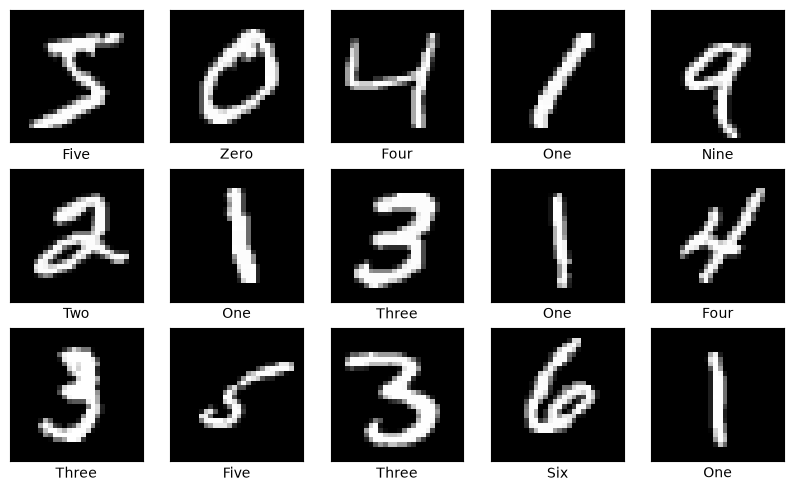

In [6]:
#Names of numbers in the dataset in order
# index 0 -> 'Zero', index 1 -> 'One' ... index 9 -> 'Nine'
col_names = ['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']

#Visualizing the digits
plt.figure(figsize=(10,10))                  # canvas size 10x10 inches
for i in range(15):                          # first 15 images
    plt.subplot(5,5,i+1)                     # 5 rows x 5 cols grid, position i+1
    plt.xticks([])                           # hide x-axis numbers
    plt.yticks([])                           # hide y-axis numbers
    plt.imshow(x_train[i], cmap='gray')      # show image in black & white
    plt.xlabel(col_names[y_train[i]])        # label below image, e.g. 'Five'
plt.show()

## 4. Preprocessing – Reshape 3D → 4D
A CNN does **not** flatten the image (that was the ANN way). It needs every image as **height × width × channels**.
Grayscale has **1 channel** (a colour image would have 3: R, G, B).
`(60000, 28, 28)` → `(60000, 28, 28, 1)`

In [7]:
# Add the channel dimension: (images, 28, 28) -> (images, 28, 28, 1)
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)   # x_train.shape[0] = 60000
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)      # x_test.shape[0]  = 10000
input_shape = (28, 28, 1)                                # shape of ONE image - given to the first layer

In [8]:
# Confirm new shape -> (60000, 28, 28, 1)
x_train.shape

(60000, 28, 28, 1)

## 5. Preprocessing – Scale pixels to 0–1
Pixels are 0–255. Dividing by 255 brings them to 0–1, which makes training faster and more stable.
(The ANN notebooks skipped this step – that is one reason their first-epoch loss was so high.)

In [9]:
# Convert from integers (uint8) to decimals (float32) so division gives decimals
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

In [10]:
# Scale: 0-255 -> 0.0-1.0
x_train /= 255
x_test /= 255

## 6. Labels – no one-hot encoding needed here
The ANN notebooks converted labels to one-hot (`5` → `[0,0,0,0,0,1,0,0,0,0]`) and used `categorical_crossentropy`.
This notebook keeps labels as plain numbers (`5`) and uses **`sparse_categorical_crossentropy`**, which does the same job without one-hot encoding.

| Labels look like | Loss to use |
|---|---|
| `5` (plain number) | `sparse_categorical_crossentropy` |
| `[0,0,0,0,0,1,0,0,0,0]` (one-hot) | `categorical_crossentropy` |

## 7. Build the CNN
```
Input 28×28×1
   ↓
Conv2D: 28 filters of size 3×3   → output 26×26×28   (finds edges / strokes)
   ↓
MaxPooling 2×2                   → output 13×13×28   (keeps strongest signal, halves size)
   ↓
Flatten                          → 4,732 numbers     (13 × 13 × 28)
   ↓
Dense 128, ReLU                  ← learns combinations of features
   ↓
Dropout 0.2                      ← switches off 20% neurons while training (less overfitting)
   ↓
Dense 10, softmax                ← probability for each digit (sum = 1)
```
- **Filter (kernel)** = a small 3×3 window that slides over the image and gives a high value where it finds a pattern it has learned (e.g. a vertical line).
- **Why 26×26?** A 3×3 window fits 28 − 3 + 1 = 26 times across and down (no padding).
- **MaxPooling 2×2** = from every 2×2 block, keep only the largest value.

In [11]:
model = Sequential()                                                  # empty model; layers are added one by one
model.add(Conv2D(28, kernel_size=(3,3), input_shape=input_shape))     # 28 filters, each 3x3 -> output 26x26x28
                                                                      # NOTE: no activation given -> 'linear' (see suggestions)
model.add(MaxPooling2D(pool_size=(2, 2)))                             # 2x2 max pooling -> 13x13x28
model.add(Flatten())                                                  # 13*13*28 = 4732 values in one row
model.add(Dense(128, activation=tf.nn.relu))                          # hidden layer: 128 neurons, ReLU
model.add(Dropout(0.2))                                               # drop 20% neurons during training
model.add(Dense(10,activation=tf.nn.softmax))                         # output: 10 digits, probabilities sum to 1

C:\Users\nisha\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
# Layers, output shapes and number of trainable parameters
# Conv2D params  = filters * (kernel_h * kernel_w * input_channels + 1)
#   Conv2D : 28 * (3*3*1 + 1)  =     280
#   MaxPool / Flatten / Dropout =       0  (nothing to learn)
#   Dense  : 128 * (4732 + 1)  = 605,824
#   Output : 10  * (128 + 1)   =   1,290
#   Total                      = 607,394 parameters
# Most parameters are in the first Dense layer - Flatten makes a very long row (4732).
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 28)          │             280 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 28)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4732)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         605,824 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 607,394 (2.32 MB)

 Trainable params: 607,394 (2.32 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Compile and train
- **optimizer** `adam` – updates weights, adjusts learning speed automatically.
- **loss** `sparse_categorical_crossentropy` – for plain-number labels (see section 6).
- **epochs=10** – the full training data is seen 10 times.
- **batch_size=32** – the default; 60,000 / 32 = 1,875 steps per epoch.
- **validation_data** – added (not in the original) so we can draw train-vs-test curves.

In [13]:
# Reference for optimizers: https://keras.io/api/optimizers/
model.compile(optimizer='adam',                          # weight-update algorithm
              loss='sparse_categorical_crossentropy',    # labels are plain numbers 0-9
              metrics=['accuracy'])                      # print accuracy every epoch

# Train and keep the history (loss & accuracy of every epoch) for graphs later
history = model.fit(x=x_train, y=y_train,                      # training images & answers
                    epochs=10,                                 # 10 full passes over the data
                    batch_size=32,                             # 32 images per weight update (default)
                    validation_data=(x_test, y_test))          # check on test data after each epoch
# Original run (without validation): training accuracy reached 0.9936 at epoch 10.

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 54s 27ms/step - accuracy: 0.9380 - loss: 0.2049 - val_accuracy: 0.9758 - val_loss: 0.0795
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 81s 28ms/step - accuracy: 0.9752 - loss: 0.0828 - val_accuracy: 0.9788 - val_loss: 0.0621
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 27ms/step - accuracy: 0.9816 - loss: 0.0587 - val_accuracy: 0.9819 - val_loss: 0.0556
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 83s 27ms/step - accuracy: 0.9851 - loss: 0.0449 - val_accuracy: 0.9836 - val_loss: 0.0540
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - accuracy: 0.9890 - loss: 0.0333 - val_accuracy: 0.9837 - val_loss: 0.0560
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 27ms/step - accuracy: 0.9902 - loss: 0.0281 - val_accuracy: 0.9819 - val_loss: 0.0646
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 27ms/step - accuracy: 0.9914 - loss: 0.0259 - val_accuracy: 0.9858 - val_loss: 0.0607
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 28ms/step - accuracy: 0.9924 -

## 9. Evaluate on the test set
Original run: **test accuracy 98.46 %** (the ANN got 95.75 %).

In [14]:
# Run the trained model on the 10,000 test images -> returns [loss, accuracy]
test_loss_cnn, test_acc_cnn = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9845 - loss: 0.0671


In [15]:
# Print accuracy rounded to 4 decimals (e.g. 0.9846 = 98.46% correct)
print('Digit MNIST CNN Test accuracy:', round(test_acc_cnn,4))

Digit MNIST CNN Test accuracy: 0.9845


## 10. Predict the test images
The model gives **10 probabilities** per image (softmax, they add up to 1). The index of the highest one = predicted digit.

In [16]:
# Predict all test images -> shape (10000, 10)
y_predict = model.predict(x_test)

# 10 probabilities of the first test image (index 0 = digit 0 ... index 9 = digit 9)
y_predict[0]

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step


array([5.26575131e-16, 1.06488955e-13, 6.95814517e-11, 1.97519490e-09,
       5.41236164e-13, 3.43322994e-15, 2.62277869e-21, 1.00000000e+00,
       8.74128447e-14, 1.65490217e-08], dtype=float32)

In [17]:
# Index of the highest probability in each row = predicted digit
y_predicts = np.argmax(y_predict, axis=1)     # axis=1 -> look across the 10 columns of each row

# Labels are already plain numbers, so no argmax is needed for y_test (unlike the ANN notebook)
print('Predicted:', y_predicts[:10])
print('Actual   :', y_test[:10])

Predicted: [7 2 1 0 4 1 4 9 5 9]
Actual   : [7 2 1 0 4 1 4 9 5 9]


## 11. Confusion matrix & classification report
- **Confusion matrix**: rows = actual digit, columns = predicted digit. The **diagonal** = correct predictions; everything else = mistakes.
- **Precision** – of all images predicted as X, how many were really X.
- **Recall** – of all real X images, how many the model found.
- **F1-score** – balance of precision & recall.
- **Support** – number of test images in that class.

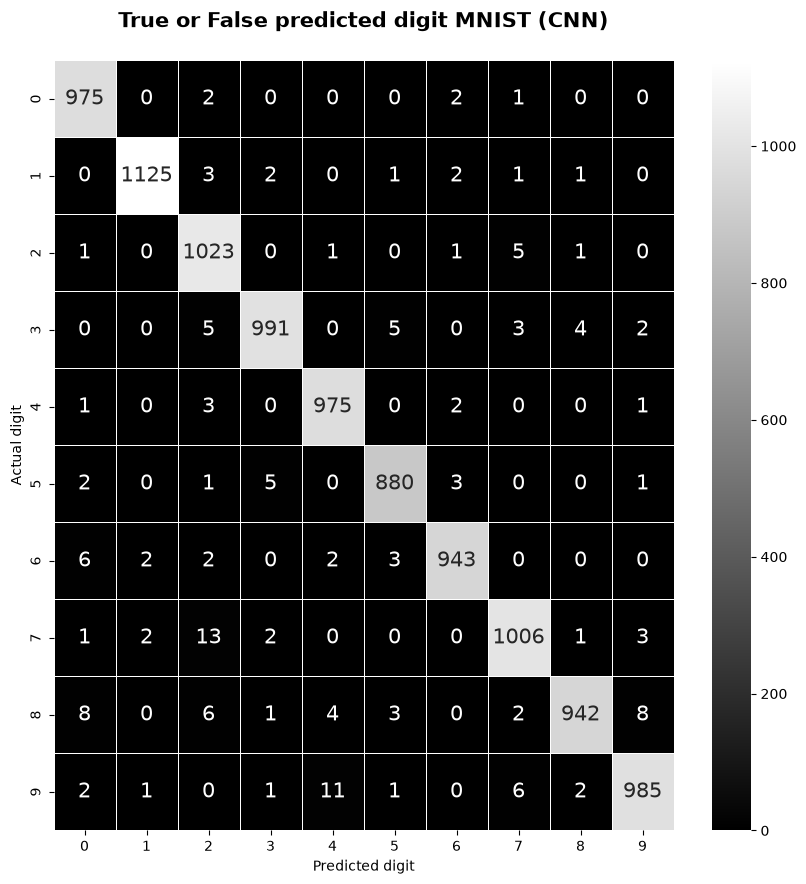

In [18]:
#Confusion matrix for Digit MNIST (CNN)
con_mat = confusion_matrix(y_test, y_predicts)   # (actual, predicted) -> 10x10 table
plt.figure(figsize=(10,10))
sns.heatmap(con_mat,
            annot=True,                # write the count inside each box
            annot_kws={'size': 15},    # font size of the counts
            linewidths=0.5,            # thin lines between boxes
            fmt="d",                   # show as whole numbers
            cmap="gray")               # grayscale colours
plt.xlabel('Predicted digit')
plt.ylabel('Actual digit')
plt.title('True or False predicted digit MNIST (CNN)\n',fontweight='bold',fontsize=15)
plt.show()

In [19]:
# Precision, recall, f1-score for each digit + overall accuracy
# target_names -> show 'Zero', 'One' ... instead of 0, 1 ...
print(classification_report(y_test, y_predicts, target_names=col_names))
# Compare with the ANN report: with a CNN, digits 3, 5 and 9 should no longer be weak.

              precision    recall  f1-score   support

        Zero       0.98      0.99      0.99       980
         One       1.00      0.99      0.99      1135
         Two       0.97      0.99      0.98      1032
       Three       0.99      0.98      0.99      1010
        Four       0.98      0.99      0.99       982
        Five       0.99      0.99      0.99       892
         Six       0.99      0.98      0.99       958
       Seven       0.98      0.98      0.98      1028
       Eight       0.99      0.97      0.98       974
        Nine       0.98      0.98      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



## 12. Training curves

In [20]:
# history.history is a dictionary - shows what was recorded every epoch
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


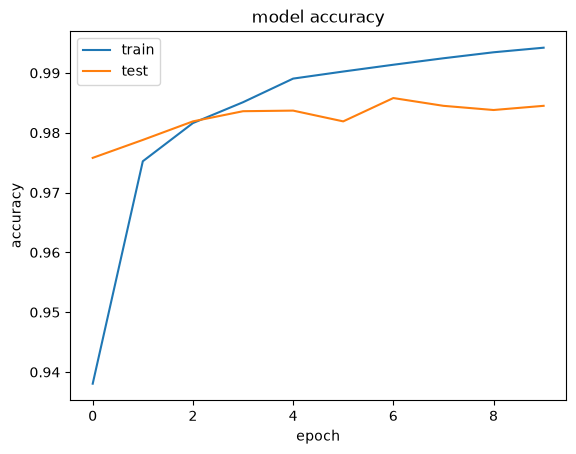

In [21]:
# ---- Accuracy curve: train vs test for every epoch ----
plt.plot(history.history['accuracy'])       # training accuracy per epoch
plt.plot(history.history['val_accuracy'])   # validation (test) accuracy per epoch
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()
# Both lines going UP together  = model is learning well
# Train UP but test FLAT/DOWN   = overfitting (memorising training data)

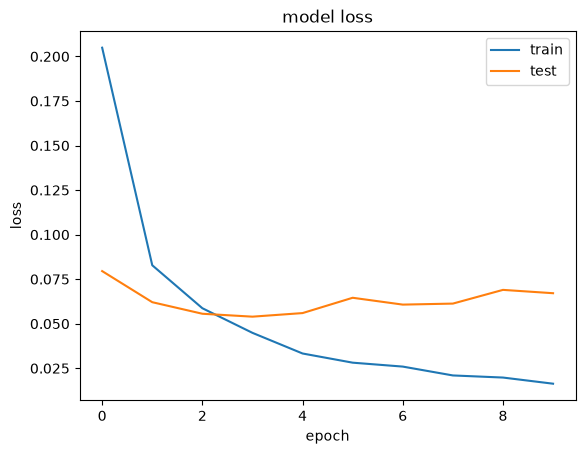

In [22]:
# ---- Loss curve: train vs test for every epoch ----
plt.plot(history.history['loss'])       # training loss (error) per epoch
plt.plot(history.history['val_loss'])   # validation (test) loss per epoch
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()
# Original run: train loss 0.018 but test loss 0.067 -> a small amount of overfitting.

## 13. Predict a single image
The model always expects a **batch**, so one image must have shape `(1, 28, 28, 1)`.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step


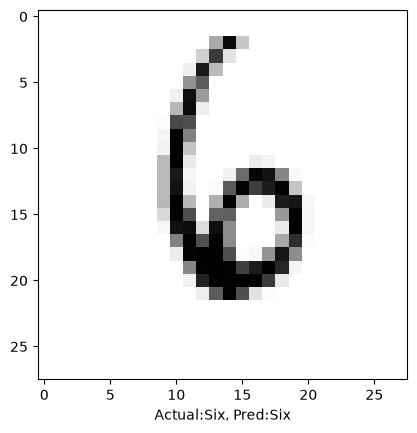

Predicted digit: 6
Confidence     : 100.0 %


In [23]:
image_index = 6900                                                  # any number from 0 to 9999
plt.imshow(x_test[image_index].reshape(28, 28), cmap='Greys')       # (28,28,1) -> (28,28) to display
pred = model.predict(x_test[image_index].reshape(1, 28, 28, 1))     # batch of 1 image -> 10 probabilities
plt.xlabel("Actual:{}, Pred:{}".format(col_names[y_test[image_index]],   # real answer
                                       col_names[pred.argmax()]))        # model's answer
plt.show()
print('Predicted digit:', pred.argmax())                            # index of the highest probability
print('Confidence     :', round(float(pred.max()) * 100, 2), '%')   # how sure the model is

## 14. Look at the mistakes (added)
Seeing *which* images the model gets wrong tells you more than the accuracy number.

Wrong predictions: 155 out of 10000


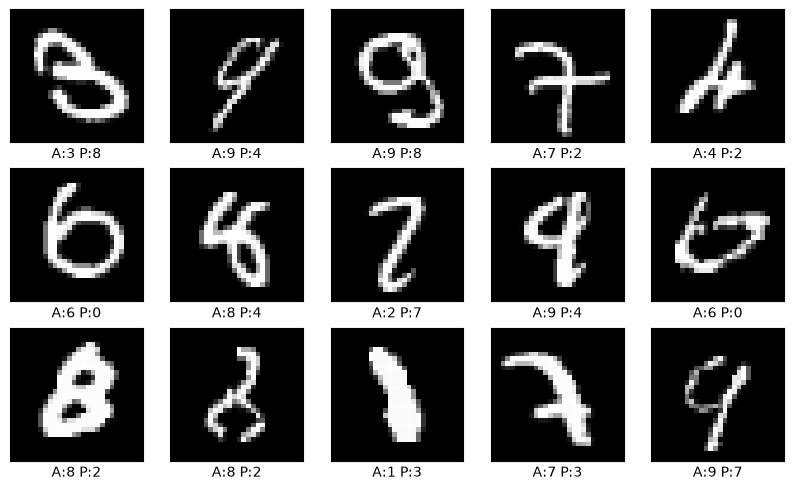

In [24]:
# Positions of all test images where prediction != actual
wrong = np.where(y_predicts != y_test)[0]
print('Wrong predictions:', len(wrong), 'out of', len(y_test))

# Show the first 15 mistakes
plt.figure(figsize=(10,10))
for i, idx in enumerate(wrong[:15]):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(x_test[idx].reshape(28,28), cmap='gray')
    plt.xlabel("A:{} P:{}".format(y_test[idx], y_predicts[idx]))   # A = actual, P = predicted
plt.show()
# Many of these are badly written digits that even a person might misread.

## 15. Save the trained model (added)
Training takes several minutes, so save the model once and load it later instead of retraining.

In [25]:
# Save the whole model (layers + learned weights) to one file
model.save('cnn_digit_model.keras')

# Later, in any notebook:
# from tensorflow.keras.models import load_model
# model = load_model('cnn_digit_model.keras')

## 16. Suggestions to improve
| # | Change | Why |
|---|---|---|
| 1 | Add `activation='relu'` to Conv2D | Right now the Conv2D layer has no activation (linear). ReLU lets it learn non-linear shapes – standard practice. |
| 2 | Add a second Conv2D + MaxPooling block | First block finds edges; a second block combines them into loops and corners. Also makes Flatten much smaller, so fewer parameters. |
| 3 | Use `EarlyStopping` | Stops training when test loss stops improving, and keeps the best weights. Saves time and avoids overfitting. |
| 4 | Use filter counts 32 / 64 | Powers of 2 are the common convention (28 works, it is just unusual). |
| 5 | Run on Google Colab with GPU | Each epoch took ~3 minutes on CPU in the original run; a Colab GPU (Runtime → Change runtime type → GPU) is much faster. |

The cell below applies 1–4. It is **optional** – run it after the cells above to compare results.

In [26]:
# ===================== OPTIONAL: IMPROVED CNN =====================
from tensorflow.keras.callbacks import EarlyStopping

model2 = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=input_shape),   # block 1: 32 filters -> 26x26x32
    MaxPooling2D((2,2)),                                             #          -> 13x13x32
    Conv2D(64, (3,3), activation='relu'),                            # block 2: 64 filters -> 11x11x64
    MaxPooling2D((2,2)),                                             #          -> 5x5x64
    Flatten(),                                                       # 5*5*64 = 1600 values
    Dense(128, activation='relu'),                                   # hidden layer
    Dropout(0.3),                                                    # drop 30% neurons while training
    Dense(10, activation='softmax'),                                 # 10 digit probabilities
])

model2.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

# Stop if val_loss does not improve for 3 epochs, and go back to the best epoch's weights
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history2 = model2.fit(x_train, y_train,
                      epochs=20,                           # upper limit - EarlyStopping usually stops sooner
                      batch_size=64,
                      validation_data=(x_test, y_test),
                      callbacks=[early_stop])

test_loss2, test_acc2 = model2.evaluate(x_test, y_test)
print('Original CNN accuracy:', round(test_acc_cnn,4))
print('Improved CNN accuracy:', round(test_acc2,4))         # usually around 0.99

C:\Users\nisha\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 57s 58ms/step - accuracy: 0.9402 - loss: 0.1965 - val_accuracy: 0.9854 - val_loss: 0.0456
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 51s 28ms/step - accuracy: 0.9812 - loss: 0.0615 - val_accuracy: 0.9887 - val_loss: 0.0369
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 23s 25ms/step - accuracy: 0.9864 - loss: 0.0457 - val_accuracy: 0.9894 - val_loss: 0.0312
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 26s 28ms/step - accuracy: 0.9887 - loss: 0.0362 - val_accuracy: 0.9917 - val_loss: 0.0274
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 26s 28ms/step - accuracy: 0.9905 - loss: 0.0300 - val_accuracy: 0.9916 - val_loss: 0.0295
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 34s 20ms/step - accuracy: 0.9918 - loss: 0.0237 - val_accuracy: 0.9920 - val_loss: 0.0250
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step - accuracy: 0.9931 - loss: 0.0215 - val_accuracy: 0.9917 - val_loss: 0.0279
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 25s 26ms/step - accuracy: 0.9941 - loss: 0.0178 - 

## 17. Summary
| Model | Test accuracy |
|---|---|
| ANN (Digit-ANN notebook) | 95.75 % |
| CNN  | 98.46 % |
| Improved CNN  | 99.20 % |

A CNN beats an ANN on images because it looks at small neighbourhoods of pixels and keeps the picture layout, instead of treating the image as 784 unrelated numbers.